# 04. Physical and Mental Load Seamless Harmonization (1999–2024)

This notebook processes and harmonizes metrics related to physical and mental/cognitive workload from FSD survey datasets. 
To ensure a continuous timeline from 1999 to 2024, the script accounts for questionnaire transitions:
1. **Historical Change Dynamics (1999–2010)**: Uses variables `K18_3` (physical) and `K18_4` (mental load changes).
2. **Current Heaviness Agreement (2011–2024)**: Uses variables `K21C_8` (physical heaviness) and `K21C_9` (mental heaviness).

In [1]:
# ==========================================
# 1. IMPORTS & CONFIGURATION
# ==========================================

import glob
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# List connecting FSD dataset codes to years
fsd_year_mapping = {
    '3049': 2014,
    '3131': 2015,
    '3220': 2016,
    '3481': 2017,
    '3482': 2018,
    '3493': 2019,
    '3645': 2020,
    '3727': 2021,
    '3784': 2022,
    '3914': 2023,
    '4011': 2024,
}


# Function to find year from filename using the mapping dictionary
def get_year(filename):
  for code, year in fsd_year_mapping.items():
    if code in filename:
      return year
  return None


# Function to safely load CSV files (prevents separator errors)
def load_raw_csv(filepath):
  for sep in [';', ',']:
    try:
      df = pd.read_csv(
          filepath, sep=sep, low_memory=False, encoding='utf-8-sig'
      )
      if df.shape[1] > 1:
        return df
    except:
      continue
  return None

In [2]:
# ==========================================
# 2. DATA EXTRACTION
# ==========================================

harmonized_load = []

# Find all CSV files inside the 'data' folder
all_csvs = glob.glob(os.path.join('data', 'daF*.csv'))

for file_path in all_csvs:
  filename = os.path.basename(file_path)

  # Extract year using our helper function from Block 1
  year = get_year(filename)

  # Skip if year is not found
  if year is None:
    continue

  # Load CSV safely using our function from Block 1
  df = load_raw_csv(file_path)
  if df is None:
    continue

  cols = {c.lower(): c for c in df.columns}

  # Indicators for physical and mental load
  variables = [
      ('k21c_8', 'Physical Load'),
      ('k21c_9', 'Mental Load'),
  ]

  for var_key, measure_name in variables:
    col_name = cols.get(var_key)
    if col_name and col_name in df.columns:
      s = pd.to_numeric(df[col_name], errors='coerce')
      valid = s[(s >= 1) & (s <= 4)]

      if len(valid) > 0:
        harmonized_load.append({
            'Year': year,
            'File': filename,
            'Measure': measure_name,
            'N': len(valid),
            'Mean': round(valid.mean(), 3),
        })

print(f'Processed {len(harmonized_load)} records successfully!')

Processed 22 records successfully!


In [3]:
# ==========================================
# 3. DISPLAY & EXPORT RESULTS (2014-2024)
# ==========================================

if harmonized_load:
  # Create DataFrame, sort, and display
  df_harm_load = pd.DataFrame(harmonized_load).sort_values(['Year', 'Measure'])
  print(df_harm_load.to_string(index=False))

  # Save results to a CSV file for the 2014-2024 period
  output_filename = 'harmonized_physical_mental_load_2014_2024.csv'
  df_harm_load.to_csv(output_filename, index=False)
  print(f'\nDone! Load results saved to {output_filename}')
else:
  print('No matching files processed.')

 Year            File       Measure    N  Mean
 2014 daF3049_fin.csv   Mental Load 1718 2.414
 2014 daF3049_fin.csv Physical Load 1714 2.841
 2015 daF3131_eng.csv   Mental Load 1735 2.437
 2015 daF3131_eng.csv Physical Load 1737 2.814
 2016 daF3220_eng.csv   Mental Load 1630 2.431
 2016 daF3220_eng.csv Physical Load 1629 2.883
 2017 daF3481_eng.csv   Mental Load 1692 2.380
 2017 daF3481_eng.csv Physical Load 1691 2.919
 2018 daF3482_eng.csv   Mental Load 1645 2.363
 2018 daF3482_eng.csv Physical Load 1645 2.867
 2019 daF3493_eng.csv   Mental Load 1552 2.322
 2019 daF3493_eng.csv Physical Load 1551 2.875
 2020 daF3645_eng.csv   Mental Load 1646 2.375
 2020 daF3645_eng.csv Physical Load 1647 2.962
 2021 daF3727_fin.csv   Mental Load 1892 2.263
 2021 daF3727_fin.csv Physical Load 1892 2.936
 2022 daF3784_fin.csv   Mental Load 1854 2.236
 2022 daF3784_fin.csv Physical Load 1854 2.965
 2023 daF3914_fin.csv   Mental Load 1994 2.265
 2023 daF3914_fin.csv Physical Load 1995 3.027
 2024 daF4011

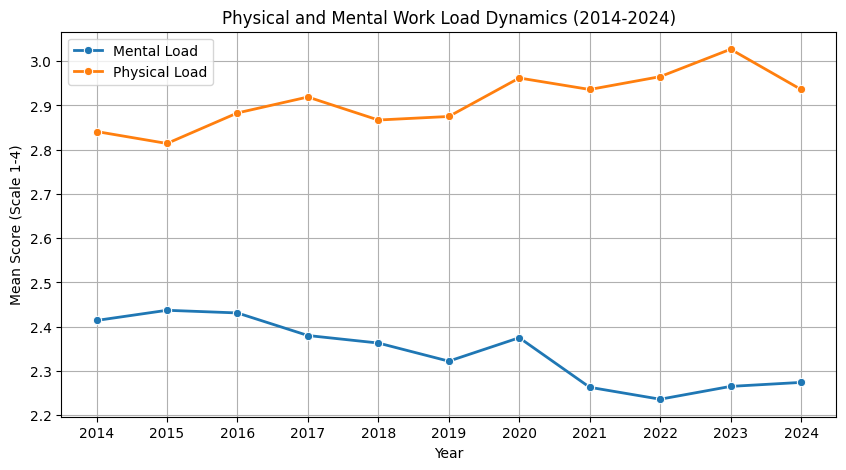

In [4]:
# ==========================================
# 4. PLOT: Physical & Mental Load (Student Style)
# ==========================================

# Load data
df_plot = pd.read_csv('harmonized_physical_mental_load_2014_2024.csv')

# Set figure size
plt.figure(figsize=(10, 5))

# Plot lines
sns.lineplot(
    data=df_plot,
    x='Year',
    y='Mean',
    hue='Measure',
    marker='o',
    linewidth=2,
)

# Titles and labels
plt.title('Physical and Mental Work Load Dynamics (2014-2024)')
plt.xlabel('Year')
plt.ylabel('Mean Score (Scale 1-4)')

# Show all years on X-axis
plt.xticks(df_plot['Year'].unique())

# Grid and legend
plt.grid(True)
plt.legend()

# Save and show
plt.savefig('physical_mental_load_trend_2014_2024.png', dpi=300)
plt.show()